Import

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

import matplotlib.pyplot as plt

Load Dataset

In [3]:
df = pd.read_csv("bihar_flood_data.csv")  # make sure path is correct
df.head()

,Date,District,Rainfall_mm,River_Level_m,Danger_Level_m,Flood,Population,Crop_Area_ha
0,2023-11-27,Araria,101.86,5.45,12.0,0,2794130,45827
1,2016-05-25,Purnia,67.95,5.67,12.0,0,1522966,57670
2,2016-01-05,Supaul,62.59,4.82,12.0,0,2428881,90847
3,2017-04-27,Begusarai,46.94,4.81,12.0,0,1743325,88113
4,2022-12-18,Jamui,48.06,4.69,12.0,0,2017991,52990


Handle Date

In [4]:
df['Date'] = pd.to_datetime(df['Date'])

df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day

df = df.drop(columns=['Date'])

Encode District

In [5]:
df = pd.get_dummies(df, columns=['District'], drop_first=True)

Define Features & Target

In [6]:
X = df.drop(columns=['Flood'])
y = df['Flood']

Train-Test Split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Scaling

In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Train SVM (Linear Kernel)

In [9]:
svm_model = SVC(
    kernel='linear',
    probability=True,
    random_state=42
)

svm_model.fit(X_train, y_train)

SVC(kernel='linear', probability=True, random_state=42)

Predictions

In [10]:
y_pred_svm = svm_model.predict(X_test)

Evaluation

In [11]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)

print("SVM Accuracy:", accuracy_svm)
print("SVM F1 Score:", f1_svm)

print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.9464285714285714
SVM F1 Score: 0.8429319371727748
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       921
           1       0.88      0.81      0.84       199

    accuracy                           0.95      1120
   macro avg       0.92      0.89      0.91      1120
weighted avg       0.95      0.95      0.95      1120



Confusion Matrix

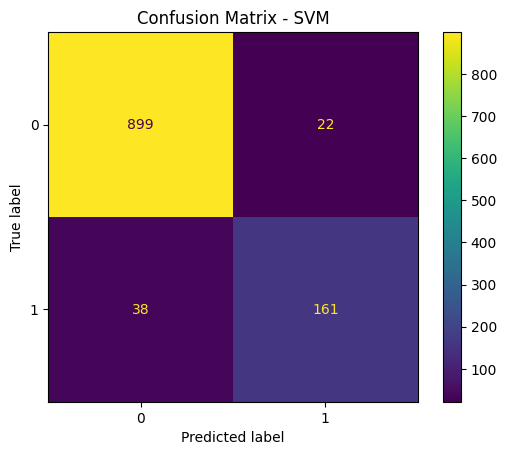

In [12]:
ConfusionMatrixDisplay.from_estimator(svm_model, X_test, y_test)
plt.title("Confusion Matrix - SVM")
plt.show()

ROC Curve

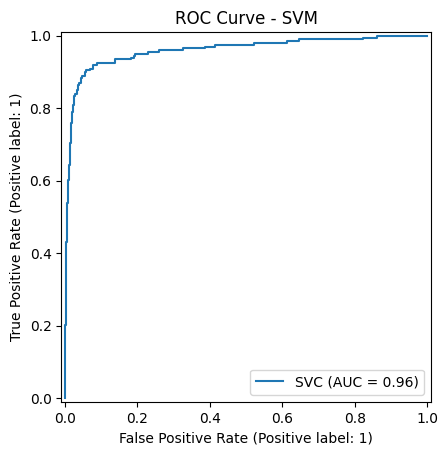

In [13]:
RocCurveDisplay.from_estimator(svm_model, X_test, y_test)
plt.title("ROC Curve - SVM")
plt.show()

Precision-Recall Curve

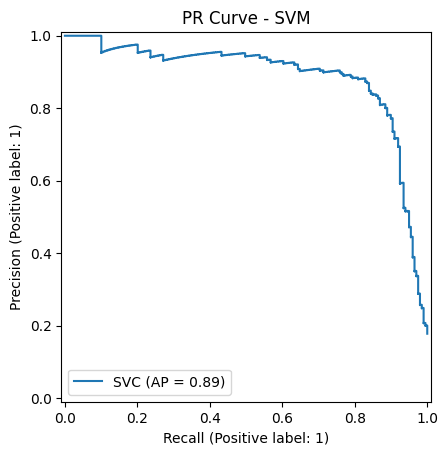

In [14]:
PrecisionRecallDisplay.from_estimator(svm_model, X_test, y_test)
plt.title("PR Curve - SVM")
plt.show()

Try Nonlinear SVM (RBF)

In [15]:
svm_rbf = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)

print("RBF SVM F1:", f1_score(y_test, y_pred_rbf))

RBF SVM F1: 0.8368421052631579
